In [31]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [5]:
data =pd.read_csv('Mall_Customers.csv')
df = pd.DataFrame(data)
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [6]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

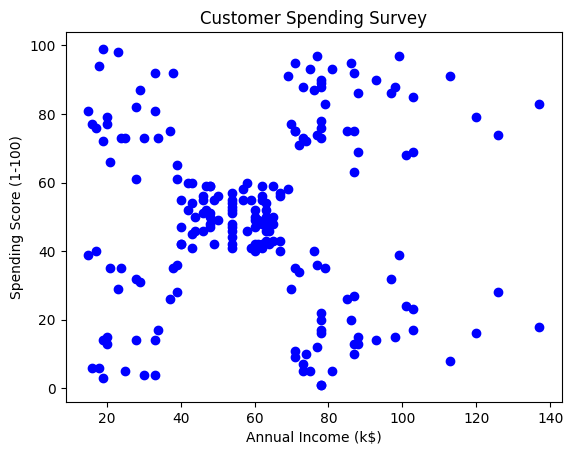

In [9]:
plt.scatter(df['Annual Income (k$)'],df['Spending Score (1-100)'],color='blue')
plt.title('Customer Spending Survey')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

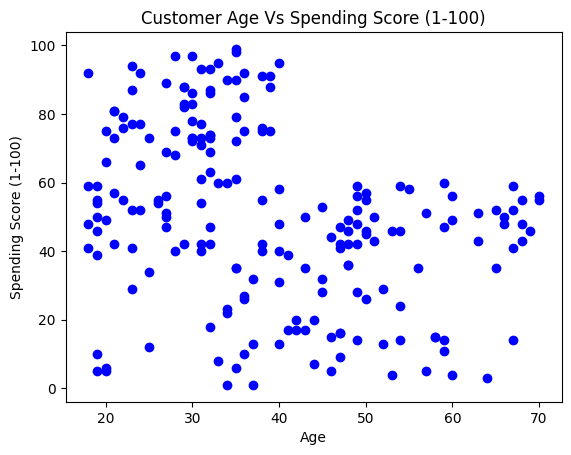

In [12]:
# scatter plot age as feature and spending score
plt.scatter(df['Age'],df['Spending Score (1-100)'],color='blue')
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Age Vs Spending Score (1-100)' ) 
plt.show()

In [15]:
X =df[['Annual Income (k$)','Spending Score (1-100)']]
X

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
195,120,79
196,126,28
197,126,74
198,137,18


Find the number of clusters using elbow method

In [17]:
inertia =[]   #what does inertia means in statistics
k = range(1,10)

for i in k:
    kmeans =KMeans(n_clusters=i).fit(X)
    inertia.append(kmeans.inertia_)

Plot the inertia to know number of clusters

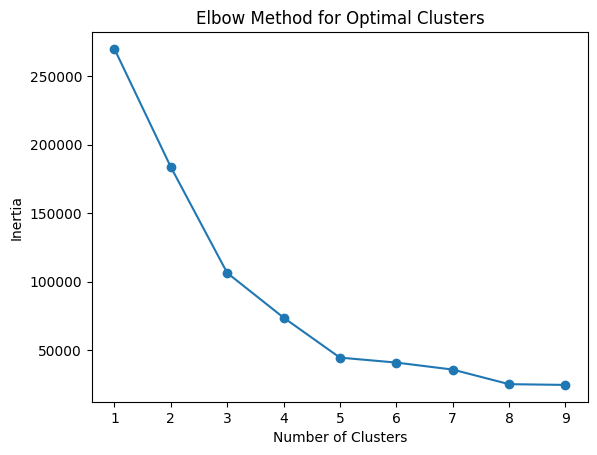

In [21]:
plt.plot(k,inertia,marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

Will go with 5 optimal clusters
High Income ,High Spending---> Premium Customers
High Income ,Low Spending --> Careful Customers
Low Income ,High Spending -->Impulsive
Low Income,Low Spendign --> Frugal Customer
Middle Segment -->Balanced Customer

In [22]:
kmeans =KMeans(n_clusters=5,n_init=5)
kmeans.fit(X)
labels = kmeans.labels_
print(labels)

[3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3
 0 3 0 3 0 3 4 3 0 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 1 2 1 4 1 2 1 2 1 4 1 2 1 2 1 2 1 2 1 4 1 2 1 2 1
 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2
 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1]


In [23]:
X['Cluster']=labels  # appending this column to data frame.
X

C:\Users\a_tas\AppData\Local\Temp\ipykernel_589804\2078758926.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Clusters']=labels


,Annual Income (k$),Spending Score (1-100),Clusters
0,15,39,3
1,15,81,0
2,16,6,3
3,16,77,0
4,17,40,3
...,...,...,...
195,120,79,1
196,126,28,2
197,126,74,1
198,137,18,2


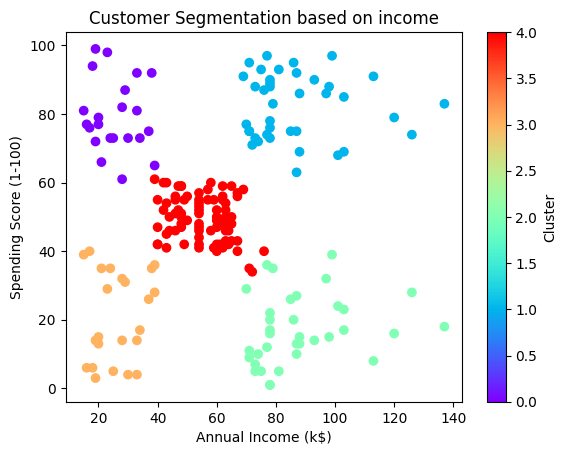

In [29]:
plt.scatter(X['Annual Income (k$)'],X['Spending Score (1-100)'],c=X['Clusters'],cmap='rainbow') #c =X['Clusters'] Means colors are taken from clusters colume
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation based on income')
plt.colorbar(label ='Cluster')
plt.show()

In [32]:
sns.scatterplot(x=X['Annual Income (k$)'], y=X['Spending Score (1-100)'], data=X, hue='Cluster', palette='rainbow')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation base on Income')
plt.show()

ValueError: Could not interpret value `Cluster` for `hue`. An entry with this name does not appear in `data`.